#### Setup

In [1]:
import os, shutil, subprocess, sys
from pathlib import Path

from IPython.display import SVG, display

from dvc_dat.ledger import Ledger, Ref

scratch_path = Path("scratch/q-values").resolve()
shutil.rmtree(scratch_path, ignore_errors=True)   # a re-run starts clean
for module_name in ("geometry", "plane", "plane.measure", "clips"):
    sys.modules.pop(module_name, None)
sys.path.insert(0, str(Path("demo_game").resolve()))   # the Video class

os.environ["DAT_KEPT"] = str(scratch_path / "kept")   # where v.seal() records local seals
L = Ledger(scratch_path / "ledger", create=True)

# Quick: values

A value is a Python object stored in the ledger by its content: its
hash is its subject, and once stored it never changes. The quick
tour: store and name a value, find it by its preds, compute values
with ledger functions, and let the ledger remember their results.

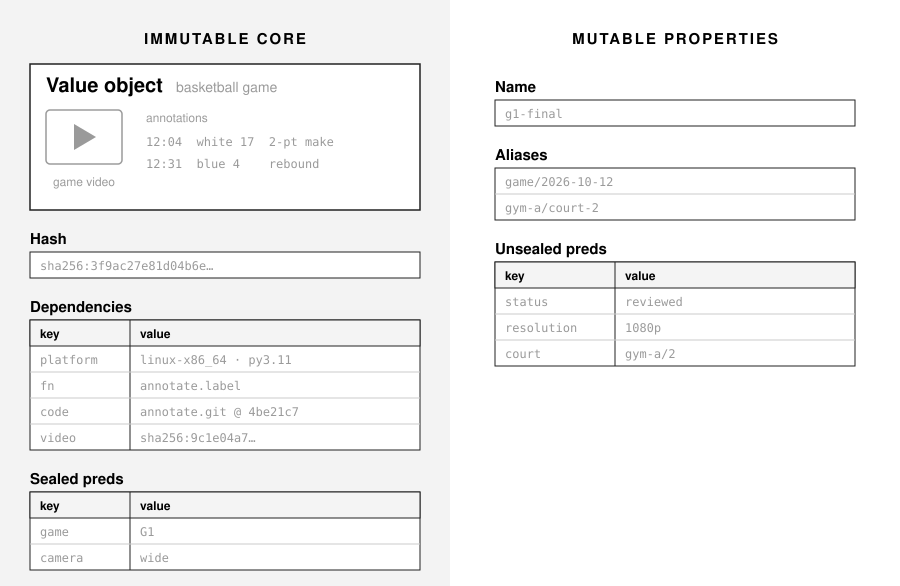

In [2]:
display(SVG(filename="q-values.svg"))   # black: the parts every value has; gray: an example

## Value objects

A value's class is a `Value` subclass in a module (here
`demo_game/game.py`), saying how the object becomes bytes and back,
and which preds (searchable string rows) it carries:

```python
@ledger_class(preds=("game", "camera", "span"))
class Video(Value):
    def __init__(self, frames: bytes):
        self.frames = frames
    def encode(self) -> bytes:
        return self.frames
    @classmethod
    def decode(cls, data: bytes, store) -> "Video":
        return cls(data)
```

### Storing a value, with its name

In [3]:
from demo_game.game import Video

video_value = Video(b"G1 wide camera, 9000 frames")
video_value.preds.update(game="G1", camera="wide")
with L.transaction(by="human:dan") as t:
    video_subject = video_value.seal(t, name="video/G1")
print("name:", video_value)                  # → name: video/G1
print("subject:", video_subject)             # → the sha256 of the content, 64 hex chars

name: video/G1
subject: 2db69ce10598da362282992a88677e9fb9ec72a60eac67313a6ea2152139b997


`seal` stores the value and names it in one step. After the seal
the value, its preds included, is frozen.

### Referring to it: by name or by hash

In [4]:
rev1 = L.at()
by_name_video = rev1.load("video/G1")
by_hash_video = rev1.load(video_subject)
print("loaded by name:", by_name_video.frames)   # → b'G1 wide camera, 9000 frames'
print("same value by hash:", by_name_video.subject == by_hash_video.subject)   # → True

loaded by name: b'G1 wide camera, 9000 frames'
same value by hash: True


### Assigning preds, and finding values by them

Preds set before the seal are written with it, as rows on the
value's subject.

In [5]:
g2_video = Video(b"G2 wide camera, 8400 frames")
g2_video.preds.update(game="G2", camera="wide")
with L.transaction(by="human:dan") as t:
    g2_subject = g2_video.seal(t, name="video/G2")
rev2 = L.at()
print("camera=wide:", rev2.values(camera="wide"))           # → [<Video video/G1>, <Video video/G2>]
print("game=G1, camera=wide:", rev2.value(game="G1", camera="wide")) # → video/G1
print("every Video:", rev2.refs(kind=Video))                # → [<Ref video/G1>, <Ref video/G2>]

camera=wide: [<Video video/G1>, <Video video/G2>]
game=G1, camera=wide: video/G1
every Video: [<Ref video/G1>, <Ref video/G2>]


`values` loads every match, `value` exactly one, `refs` the
matches unloaded.

#### Updating a pred

The preds the class declares (`game`, `camera`, `span`) are sealed
with the value and never change. Any other pred is a row written
beside it: assigned in one transaction, updated in the next, and
the finders follow it.

In [6]:
with L.transaction(by="human:dan") as t:
    t[g2_subject, "status"] = "raw"
rev3 = L.at()
with L.transaction(by="human:dan", why="G2 reviewed") as t:
    t[g2_subject, "status"] = "reviewed"
print("raw, before the update:", rev3.values(status="raw"))        # → [<Video video/G2>]
print("raw, after:", L.at().values(status="raw"))      # → []
print("reviewed, after:", L.at().values(status="reviewed")) # → [<Video video/G2>]

raw, before the update: [<Video video/G2>]
raw, after: []
reviewed, after: [<Video video/G2>]


### Values are immutable; their names, aliases and preds are not

The bytes behind a hash, and the preds sealed with them, never
change. A name, an alias or any other pred is a row beside the
value, and rows can be written any time.

#### Adding an alias

An alias is a `db/alias` row pointing at the value's subject. Any
number may point at one value; its name is the alias written
latest.

In [7]:
with L.transaction(by="human:dan") as t:
    t.add("raw/G1/wide-camera", "db/alias", video_subject)
camera_ref = Ref(L.at(), "video/G1")
print("aliases:", sorted(camera_ref.aliases))   # → ['raw/G1/wide-camera', 'video/G1']
print("name:", camera_ref.name)              # → raw/G1/wide-camera

aliases: ['raw/G1/wide-camera', 'video/G1']
name: raw/G1/wide-camera


A `Ref` points at a value without fetching its bytes.

#### Renaming: a new alias, the old one removed

In [8]:
with L.transaction(by="human:dan") as t:
    t.add("game/G2/baseline", "db/alias", g2_subject)
    t.remove("video/G2", "db/alias", g2_subject)
g2_ref = Ref(L.at(), g2_subject)
print("aliases:", g2_ref.aliases, " name:", g2_ref.name)   # → ['game/G2/baseline'] game/G2/baseline

aliases: ['game/G2/baseline']  name: game/G2/baseline


#### Adding and changing a pred

A pred the class never declared can be added too.

In [9]:
with L.transaction(by="human:dan", why="format survey") as t:
    for video_ref in L.at().refs(kind=Video):
        t.add(video_ref.subject, "resolution", "1080p")
with L.transaction(by="human:dan", why="G2 was re-encoded") as t:
    t[g2_subject, "resolution"] = "720p"
print("G1 resolution:", Ref(L.at(), video_subject).preds["resolution"])   # → 1080p
print("G2 resolution:", Ref(L.at(), g2_subject).preds["resolution"])      # → 720p

G1 resolution: 1080p
G2 resolution: 720p


## Ledger functions

A ledger function is a Python function the ledger knows by dotted
name; it takes the revision first, and its result is sealed as a
value. It lives in a git repository, so the ledger can record
exactly which code ran.

### Set up repo and code

One git repository, `geometry`, holds both functions used below:
`geometry.distance` runs in this process; `plane.measure.length`
runs sandboxed. Each package declares its version, `__version__`.

In [10]:
# setup: create the repo in a folder, with these source files, and commit them
repo_path = scratch_path / "geometry"
(repo_path / "plane").mkdir(parents=True)
(repo_path / "geometry.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn

__version__ = "5.3.9"

@ledger_fn
def distance(rev, a, b=(0, 0)) -> float:
    return math.dist(a, b)
''')

(repo_path / "plane/__init__.py").write_text('''\
__version__ = "2.7.1"
''')

(repo_path / "plane/measure.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn

@ledger_fn
def length(rev, a, b) -> float:
    return math.dist(a, b) * 0.5     # metres per unit
''')

git_cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com"]
subprocess.run(git_cmd + ["init", "-q"], cwd=repo_path, check=True)
subprocess.run(git_cmd + ["add", "."], cwd=repo_path, check=True)
subprocess.run(git_cmd + ["commit", "-q", "-m", "geometry and plane"], cwd=repo_path, check=True)

sys.path.insert(0, str(repo_path))

### Accessing and using Python functions

In [11]:
distance_fn = L.at().load_fn("geometry.distance")
print("fn:", distance_fn, " code:", distance_fn.code)
# → fn: geometry.distance@5.3.9  code: geometry@5.3.9
hypotenuse_value = distance_fn(a=(3, 4))
print("result:", hypotenuse_value.obj, " sealed at:", hypotenuse_value.sealed)
# → result: 5.0  sealed at: <the seal's moment>

fn: geometry.distance@5.3.9  code: geometry@5.3.9
result: 5.0  sealed at: 2026-10-25T06:48:35Z


`load_fn` finds the function; calling it runs it and seals the
plain `float` it returns as a value (`.obj` unboxes it). A
function prints as its name `@` its version; `code` is the code it
is loaded from, the package `geometry` at the version it declares.

### Sandboxed functions

A sandboxed function runs isolated, seeing only its mounted source
folder. A mount is two rows: the folder, and the repo that holds
it. Its version is the mounted package's `__version__`, read after
importing it; the checksum of the files it loaded (`sha`) is its
identity.

In [12]:
with L.transaction(by="human:dan") as t:
    t.add("db/mount/plane", "db/root", "plane")
    t.add("db/mount/plane", "db/repo", "geometry")

length_fn = L.at().load_fn("plane.measure.length")
segment_value = length_fn(a=(0, 0), b=(3, 4))
print("fn:", length_fn, " code:", length_fn.code, " sandboxed:", length_fn.code.sandboxed)
# → fn: plane.measure.length@2.7.1  code: plane@2.7.1  sandboxed: True
print("result:", segment_value.obj)                 # → result: 2.5

fn: plane.measure.length@2.7.1  code: plane@2.7.1  sandboxed: True
result: 2.5


#### A sandbox is a snapshot of the code

Loading a sandboxed function takes a snapshot of the code it runs;
`code` is that snapshot, the sandbox: `modules` are the files in
it, `version` the name the package gives it. The function's
`subject` is its name under the snapshot's hash. Every result
records the function as it ran, every module it loaded
(`plane/__init__.py` too), among its dependencies.

In [13]:
sandbox = length_fn.code
print("sandbox:", sandbox, " version:", sandbox.version, " modules:", sandbox.modules)
# → sandbox: plane@2.7.1  version: 2.7.1  modules: ['plane/__init__.py', 'plane/measure.py']
print("function identity:", length_fn.subject)     # → db/fn/plane.measure.length/bab093250d0dffef
print("result depends on:", segment_value.dependencies)
# → {'fn': 'db/fn/plane.measure.length/04ebdaea96da6a7b', 'platform': <this machine>}

sandbox: plane@2.7.1  version: 2.7.1  modules: ['plane/__init__.py', 'plane/measure.py']
function identity: db/fn/plane.measure.length/bab093250d0dffef
result depends on: {'fn': 'db/fn/plane.measure.length/04ebdaea96da6a7b', 'platform': 'darwin-arm64-py3.11'}


Change the code, and bump the version with it, and the function is
a new one, with a new identity. The old result still names the
version that made it.

In [14]:
measure_path = repo_path / "plane/measure.py"
measure_path.write_text(measure_path.read_text().replace("* 0.5 ", "* 0.25"))
(repo_path / "plane/__init__.py").write_text('__version__ = "2.7.2"\n')
subprocess.run(git_cmd + ["commit", "-q", "-am", "quarter metres"], cwd=repo_path, check=True)
new_length_fn = L.at().load_fn("plane.measure.length")
print("new fn:", new_length_fn)                     # → new fn: plane.measure.length@2.7.2
print("new identity:", new_length_fn.subject)
# → new identity: db/fn/plane.measure.length/f000d89a5e3f336f
print("new result:", new_length_fn(a=(0, 0), b=(3, 4)).obj)    # → 1.25
print("old result still names:", segment_value.dependencies["fn"], " and holds:", segment_value.obj)
# → db/fn/plane.measure.length/04ebdaea96da6a7b 2.5

new fn: plane.measure.length@2.7.2
new identity: db/fn/plane.measure.length/f000d89a5e3f336f


new result: 1.25
old result still names: db/fn/plane.measure.length/04ebdaea96da6a7b  and holds: 2.5


## Ledger evaluation

`rev.run(name, **keys)` is a lookup and a call, traced: the result
records what it depended on, and is remembered, so asking again is
answered from the ledger.

In [15]:
far_value = L.at().run("geometry.distance", a=(6, 8))
print("result:", far_value.obj)                       # → 10.0
print("depends on:", sorted(far_value.dependencies))      # → ['code/geometry', 'fn', 'platform']
top_id = L.at().id

again_value = L.at().run("geometry.distance", a=(6, 8))
print("same value:", again_value.subject == far_value.subject, " nothing written:",
      L.at().id == top_id)                 # → True True: a hit, nothing written

result: 10.0
depends on: ['code/geometry', 'fn', 'platform']


same value: True  nothing written: True


The dependencies are the code's commit, the function, and the
platform.

### Step by step

`run` is three separable steps: load the function, run it with its
provenance captured, put the result on the ledger. `seal=False`
stops after the second, so the result can be looked at first;
`.seal(t)` is the third. Nothing runs twice.

In [16]:
distance_fn = L.at().load_fn("geometry.distance")          # (1) load the function
draft_value = distance_fn(a=(9, 12), seal=False)           # (2) run it, provenance captured, nothing kept
print("draft:", draft_value.obj, " sealed:", draft_value.sealed)   # → 15.0 None
print("draft depends on:", sorted(draft_value.dependencies))       # the trace rides on the draft
with L.transaction(by="human:dan", why="keep it") as t:    # (3) put it on the ledger
    draft_value.seal(t)
kept_value = L.at().run("geometry.distance", a=(9, 12))    # the same call: a hit
print("hit:", kept_value.subject == draft_value.subject)   # → True: nothing ran

draft: 15.0  sealed: None
draft depends on: ['code/geometry', 'fn', 'platform']


hit: True


`seal=` says how far a call goes: `"get"` only looks, `False` runs
and keeps nothing, `True` also seals the result on this machine, a
ledger or a transaction saves it there. Left out, it saves to the
function's own ledger, as `run` does.

## Provenance

A value a ledger function returns records what it depended on: the
function at its version, the code's commit, the platform, and every
name and value it read. That record is its provenance.

### When a name moves, a result goes stale

A result records every name it read and the value it pointed at.
Seal a new video under the same name and the name moves; the old
result no longer matches the ledger, so `run` recomputes.

In [17]:
(repo_path / "clips.py").write_text('''\
from dvc_dat.ledger import ledger_fn
from demo_game.game import Video

@ledger_fn
def clip(rev, *, video: str, start: int, end: int) -> Video:
    return Video(rev.load(video).frames[start:end])
''')

subprocess.run(git_cmd + ["add", "."], cwd=repo_path, check=True)
subprocess.run(git_cmd + ["commit", "-q", "-m", "clips"], cwd=repo_path, check=True)

# Computing a Value on the Ledger
opening_clip = L.at().run("clips.clip", video="video/G1", start=0, end=8)
print("opening clip:", opening_clip.frames)                 # → b'G1 wide '

retake_video = Video(b"G1 retake, 9100 frames")
retake_video.preds.update(game="G1", camera="wide")
with L.transaction(by="human:dan", why="the retake") as t:
    retake_video.seal(t, name="video/G1")   # the name moves
rev4 = L.at()
print("opening clip still holds:", opening_clip.matches(rev4))          # → False: video/G1 moved
retake_clip = rev4.run("clips.clip", video="video/G1", start=0, end=8)
print("retake clip:", retake_clip.frames)                  # → b'G1 retak'
print("first video, by hash:", rev4.load(video_subject).frames)     # → b'G1 wide camera, 9000 frames'

opening clip: b'G1 wide '
opening clip still holds: False


retake clip: b'G1 retak'
first video, by hash: b'G1 wide camera, 9000 frames'


A value never changes; a name moves. The old video and the old
clip stay, found by their hashes.

### What a result depends on

In [18]:
for dep_key, dep_value in sorted(retake_clip.dependencies.items()):
    print(f"{dep_key[:28]:30}= {dep_value[:56]}")

code/geometry                 = 9e3ef5ab
fn                            = db/fn/clips.clip/23b49920800da19f
platform                      = darwin-arm64-py3.11
ref:demo_game.game.Video:d01  = ref:demo_game.game.Video:d010f249b04e397f3178803c474e458
video/G1 db/alias             = ref:demo_game.game.Video:d010f249b04e397f3178803c474e458


- `code/geometry`: the commit of the repo the function ran from.
- `fn`: the function at its version, as for the sandbox above.
- `platform`: the machine it ran on.
- `ref:…`: the video bytes it loaded.
- `video/G1 db/alias`: the value the name `video/G1` pointed at.

That last row is how `matches` knew the opening clip was stale: it
names the first video, and the name has since moved to the retake.

In [19]:
first_hash = rev4.load(video_subject).hash
print("opening clip read the first video:", opening_clip.dependencies["video/G1 db/alias"].endswith(first_hash))   # → True: the first video
print("retake clip read the retake:", retake_clip.dependencies["video/G1 db/alias"].endswith(retake_video.hash))   # → True: the retake

opening clip read the first video: True
retake clip read the retake: True


### Sealing a value by hand

Sealing fixes a value: its bytes' hash and its preds, so it can be
checked but not changed. Saving puts the sealed value on the
ledger's timeline. `v.seal(t)` does both at once; here they are
apart.

In [20]:
highlight_video = Video(b"G1 highlights, 600 frames")      # 1. make a value
highlight_video.preds.update(game="G1", camera="wide")

print("sealed, hash:", highlight_video.seal()[:12])     # 2. seal it, on this machine only
print("sealed at:", highlight_video.sealed)             # → <the seal's moment>
try:
    highlight_video.preds["camera"] = "baseline"
except Exception as error:
    print("change refused:", type(error).__name__, error)    # → TypeError cannot modify a sealed value's preds
print("G1 videos on the ledger:", L.at().values(game="G1"))   # not on the timeline yet

with L.transaction(by="human:dan", why="keep the highlights") as t:   # 3. keep it
    highlight_video.seal(t, name="video/G1/highlights")
print("G1 videos on the ledger:", L.at().values(game="G1"))   # now it is

sealed, hash: 75b825dc06c0
sealed at: 2026-10-25T06:48:38Z
change refused: TypeError cannot modify a sealed value's preds
G1 videos on the ledger: [<Video raw/G1/wide-camera>, <Video video/G1>]
G1 videos on the ledger: [<Video raw/G1/wide-camera>, <Video video/G1>, <Video video/G1/highlights>]
